# Member 4 — Categorical and Time EDA

Owner: IT24104068

Purpose: Perform Exploratory Data Analysis on categorical and time-related features.

## Cell 1 — Load the training dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load validated dataset and saved split
data_path = Path("../../data/processed/hotel_bookings_validated_phase3.csv")
split_path = Path("../../results/splits/group_holdout_indices.npz")
RESULTS_DIR = Path("../../results/eda")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path)
splits = np.load(split_path)

# Use training data for EDA
train = df.iloc[splits["train_idx"]].copy()

print("Training dataset shape:", train.shape)
print("Cancellation rate:", f"{train['is_canceled'].mean():.2%}")

display(train[[
    "hotel",
    "market_segment",
    "arrival_date_month",
    "is_canceled"
]].head())


Training dataset shape: (95334, 32)
Cancellation rate: 37.01%


,hotel,market_segment,arrival_date_month,is_canceled
0,Resort Hotel,Direct,July,0
1,Resort Hotel,Direct,July,0
2,Resort Hotel,Direct,July,0
3,Resort Hotel,Corporate,July,0
7,Resort Hotel,Direct,July,0


## Cell 2 — Cancellation Rate by Market Segment

,bookings,cancellation_rate
market_segment,,
Groups,16078,0.611
Online TA,45165,0.369
Offline TA/TO,19075,0.336
Aviation,193,0.233
Corporate,4161,0.181
Direct,10086,0.153
Complementary,575,0.122


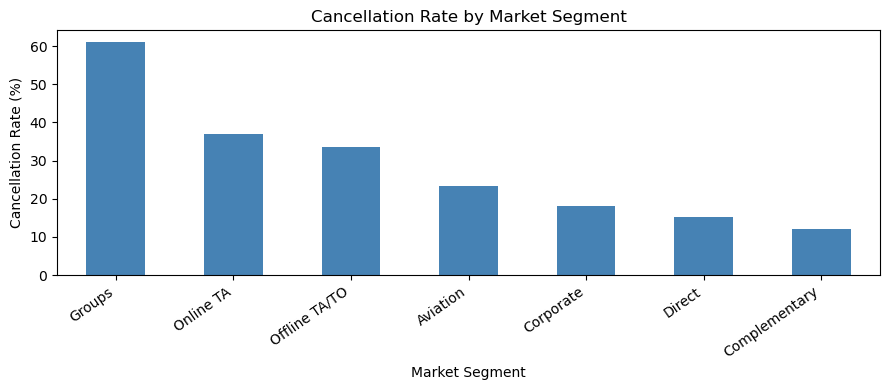

In [7]:

# Cancellation analysis by market segment
segment = train.groupby("market_segment")["is_canceled"].agg(
    bookings="size",
    cancellation_rate="mean"
)

# Exclude segments with fewer than 100 bookings
segment = segment[segment["bookings"] >= 100]

# Sort by cancellation rate
segment = segment.sort_values("cancellation_rate", ascending=False)

display(segment.round(3))

# Visualize cancellation rates
(segment["cancellation_rate"] * 100).plot(
    kind="bar",
    figsize=(9, 4),
    color="steelblue"
)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "m4_market_segment_cancellation.png", dpi=150)
plt.show()


## Cell 3 — Cancellation Rate by Arrival Month

,bookings,cancellation_rate
arrival_date_month,,
January,4721,0.305
February,6402,0.322
March,7680,0.307
April,8800,0.401
May,9493,0.404
June,8913,0.415
July,10078,0.386
August,11159,0.381
September,8240,0.389


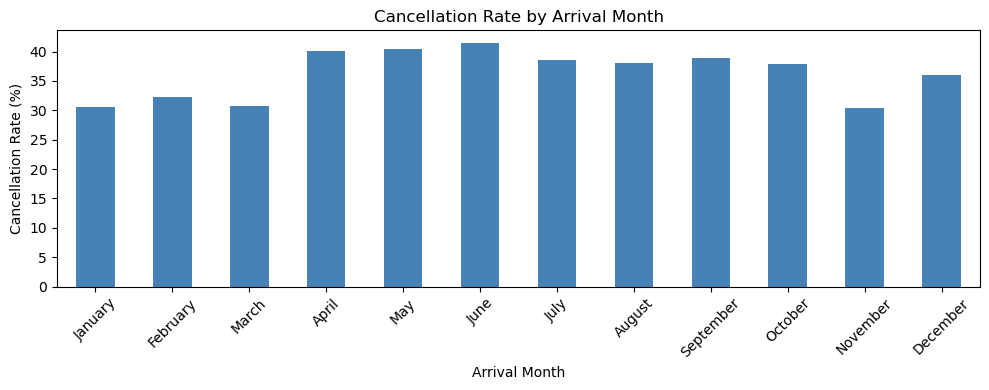

In [8]:

# Define the correct month order
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Cancellation analysis by arrival month
monthly = train.groupby("arrival_date_month")["is_canceled"].agg(
    bookings="size",
    cancellation_rate="mean"
).reindex(months)

display(monthly.round(3))

# Visualize monthly cancellation rates
(monthly["cancellation_rate"] * 100).plot(
    kind="bar",
    figsize=(10, 4),
    color="steelblue"
)

plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "m4_arrival_month_cancellation.png", dpi=150)
plt.show()


## Cell 4 — Cancellation Rate by Hotel Type

,bookings,cancellation_rate
hotel,,
City Hotel,63400,0.416
Resort Hotel,31934,0.280


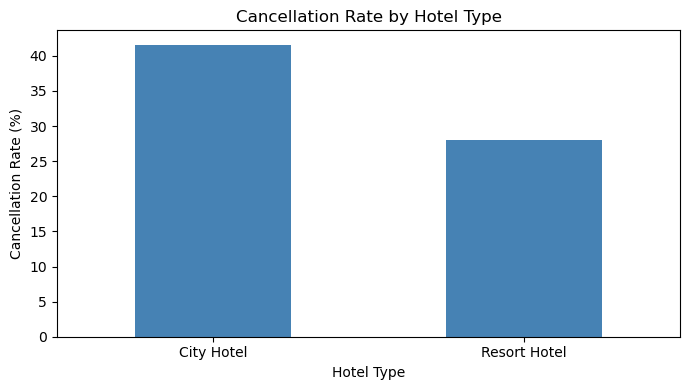

In [9]:

# Cancellation analysis by hotel type
hotel_analysis = train.groupby("hotel")["is_canceled"].agg(
    bookings="size",
    cancellation_rate="mean"
)

hotel_analysis = hotel_analysis.sort_values(
    "cancellation_rate", ascending=False
)

display(hotel_analysis.round(3))

# Visualize cancellation rates
(hotel_analysis["cancellation_rate"] * 100).plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue"
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "m4_hotel_type_cancellation.png", dpi=150)
plt.show()


### Hotel Type Analysis

City Hotels recorded a cancellation rate of 41.6%, compared with 28.0% for Resort Hotels. City Hotels also accounted for a larger number of bookings.

These findings suggest that cancellation patterns differ between hotel types. The `hotel` feature will therefore be retained for model development. Hotel managers may also consider hotel-specific approaches to monitoring cancellation risk.

## Categorical and Time-Based EDA Conclusion

The exploratory analysis identified meaningful differences in booking cancellation rates across market segments, arrival months, and hotel types.

Group bookings showed the highest cancellation rate among major market segments, while June recorded the highest monthly cancellation rate. City Hotels also experienced higher cancellation rates than Resort Hotels.

These findings support retaining `market_segment`, `arrival_date_month`, and `hotel` as candidate predictors. They also highlight areas where hotel revenue and operations teams could prioritize cancellation-risk monitoring.

The analysis was conducted using training data only to preserve the independence of the held-out test set.